# Лабораторная работа 6. Ford vs Ferrari
Оспан Әсел Ғалымжанқызы · Казахский национальный университет имени аль-Фараби

Сравните ResNet18 и MobileNetV3-Small на одном стратифицированном разбиении.
Блокнот вызывает приложенный Python_Code/Chapter_06/ford_ferrari_compare.py.
Нужны PyTorch, совместимый torchvision и Pillow. При первом запуске веса ImageNet
загружаются, если их ещё нет в выбранном кэше.

## 1. Учебная матрица ошибок
Строки соответствуют истинным классам, столбцы — предсказанным.
Для каждого класса вычислите 2TP/(сумма строки + сумма столбца).
Macro-F1 — среднее значений по классам с одинаковым весом.

In [1]:
def accuracy_macro_f1(matrix):
    """Строки — истинные классы, столбцы — предсказанные."""
    support = [sum(row) for row in matrix]
    predicted = [sum(column) for column in zip(*matrix)]
    correct = [row[i] for i, row in enumerate(matrix)]
    class_f1 = []
    for tp, true_count, predicted_count in zip(correct, support, predicted):
        denominator = true_count + predicted_count
        class_f1.append(2 * tp / denominator if denominator else 0.0)
    return sum(correct) / sum(support), sum(class_f1) / len(class_f1)



from math import isclose

example = [[8, 1, 1], [1, 2, 1], [0, 1, 1]]
acc, macro = accuracy_macro_f1(example)
assert isclose(acc, 11 / 16)
assert isclose(macro, (16 / 19 + 4 / 8 + 2 / 5) / 3)
print(f"Учебный пример: accuracy={acc:.4f}, macro-F1={macro:.4f}")

Учебный пример: accuracy=0.6875, macro-F1=0.5807


## 2. Архив и настройки запуска
Храните блокнот вместе с папкой Python_Code. Если исходный архив находится
по другому пути, измените ARCHIVE или задайте FORD_FERRARI_ARCHIVE до запуска ядра.
CACHE_DIR используется для вложенного train.zip, TORCH_HOME — для весов ImageNet.
Предусмотрите свободное место для временной копии вложенного архива.

SHORT = True задаёт 40 тренировочных, 20 валидационных и 20 тестовых объектов,
по 4/2/2 на категорию. При SHORT = False используются 300/100/100 и 15 эпох.
Обе модели в каждом опыте получают один набор индексов.

In [2]:
import os
from pathlib import Path
import sys
from tempfile import gettempdir

cwd = Path.cwd().resolve()
book = next(
    (p for p in (cwd, *cwd.parents) if (p / "Python_Code/Chapter_06/ford_ferrari_compare.py").is_file()),
    None,
)
if book is None:
    raise FileNotFoundError("Откройте блокнот из папки учебника вместе с Python_Code.")
archive_default = book.parent / "СРО 2 Феррари" / "sf-dl-car-classification.zip"
ARCHIVE = Path(os.environ.get("FORD_FERRARI_ARCHIVE", str(archive_default)))
CACHE_DIR = Path(os.environ.get("FORD_FERRARI_CACHE", str(Path(gettempdir()) / "ford-ferrari")))
TORCH_HOME = os.environ.get("FORD_FERRARI_TORCH_HOME", "")
SHORT = True
SEED = 42
if not ARCHIVE.is_file():
    raise FileNotFoundError("Укажите ARCHIVE для sf-dl-car-classification.zip.")
sys.path.insert(0, str(book / "Python_Code/Chapter_06"))
from ford_ferrari_compare import main

train_count, val_count, test_count, candidates, epochs = (4, 2, 2, 14, 2) if SHORT else (30, 10, 10, 80, 15)
argv = [
    "--archive", str(ARCHIVE), "--cache-dir", str(CACHE_DIR),
    "--train-per-class", str(train_count), "--val-per-class", str(val_count),
    "--test-per-class", str(test_count), "--candidates-per-class", str(candidates),
    "--epochs", str(epochs), "--batch-size", "16", "--seed", str(SEED),
]
if TORCH_HOME:
    argv.extend(["--torch-home", TORCH_HOME])
print(f"Режим: {'короткий' if SHORT else 'полный'}, seed={SEED}, эпох={epochs}")

Режим: короткий, seed=42, эпох=2


## 3. Обучение голов и контроль метрик
Изображения группируются по точным и близким совпадениям до разбиения.
Линейные головы учатся на фиксированных признаках. Лучшая эпоха определяется
валидационной macro-F1. Локальный тест применяется для отчёта по каждой ветви.

In [3]:
results = main(argv)
assert len(results) == 2
for name, outcome in results.items():
    matrix = outcome["confusion"]
    assert len(matrix) == 10 and all(len(row) == 10 for row in matrix)
    assert all(sum(row) == test_count for row in matrix)
    acc, macro = accuracy_macro_f1(matrix)
    assert isclose(acc, outcome["accuracy"], abs_tol=1e-7)
    assert isclose(macro, outcome["macro_f1"], abs_tol=1e-7)
    assert outcome["latency_p95_ms"] >= outcome["latency_p50_ms"] > 0
    print(f"{name}: сверено по матрице accuracy={acc:.4f}, macro-F1={macro:.4f}")

readable=140 unreadable=0 groups=140 multi_item_groups=0 conflicting_groups=0 usable_per_class=[14, 14, 14, 14, 14, 14, 14, 14, 14, 14]
torch=2.10.0+cpu torchvision=0.25.0+cpu seed=42 train=40 val=20 test=20



ResNet18: parameters=11181642 trainable=5130


epoch=1 train_loss=4.4383 val_accuracy=0.1000 val_macro_f1=0.0182
epoch=2 train_loss=2.9251 val_accuracy=0.0500 val_macro_f1=0.0143


best_epoch=1 val_macro_f1=0.0182 test_accuracy=0.1000 test_macro_f1=0.0182 latency_p50_ms=157.472 latency_p95_ms=181.909
confusion_matrix (rows=true, columns=predicted; classes=0..9)
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0
  0   0   0   0   0   0   0   0   2   0



MobileNetV3-Small: parameters=1528106 trainable=10250


epoch=1 train_loss=3.1904 val_accuracy=0.0500 val_macro_f1=0.0222
epoch=2 train_loss=0.7529 val_accuracy=0.1000 val_macro_f1=0.0452


best_epoch=2 val_macro_f1=0.0452 test_accuracy=0.2500 test_macro_f1=0.2054 latency_p50_ms=14.513 latency_p95_ms=23.437
confusion_matrix (rows=true, columns=predicted; classes=0..9)
  1   0   0   0   0   0   0   0   1   0
  2   0   0   0   0   0   0   0   0   0
  2   0   0   0   0   0   0   0   0   0
  0   0   0   0   0   0   0   1   1   0
  0   0   0   0   1   1   0   0   0   0
  1   0   0   0   1   0   0   0   0   0
  2   0   0   0   0   0   0   0   0   0
  2   0   0   0   0   0   0   0   0   0
  1   0   0   0   0   0   0   0   1   0
  0   0   0   0   0   0   0   0   0   2
ResNet18: сверено по матрице accuracy=0.1000, macro-F1=0.0182
MobileNetV3-Small: сверено по матрице accuracy=0.2500, macro-F1=0.2054


## 4. Сопоставление двух систем
Посмотрите на внедиагональные ячейки. Выберите заранее требование к задержке
и сравнивайте модели по валидационной метрике в допустимой области.
p50 и p95 измерены для прямого прохода по готовому тензору на CPU.

| Модель | Val macro-F1 | Test accuracy | Test macro-F1 | p50, мс | p95, мс |
|:---|---:|---:|---:|---:|---:|
| ResNet18 | 0.0182 | 0.1000 | 0.0182 | 157.472 | 181.909 |
| MobileNetV3-Small | 0.0452 | 0.2500 | 0.2054 | 14.513 | 23.437 |

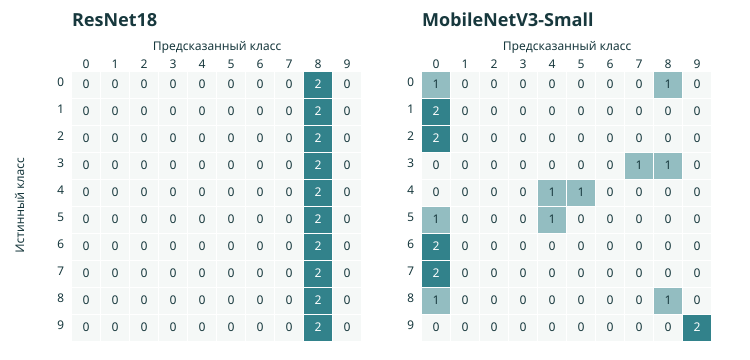

In [4]:
from IPython.display import Markdown, SVG, display

lines = [
    "| Модель | Val macro-F1 | Test accuracy | Test macro-F1 | p50, мс | p95, мс |",
    "|:---|---:|---:|---:|---:|---:|",
]
for name, item in results.items():
    lines.append(
        f"| {name} | {item['val_macro_f1']:.4f} | {item['accuracy']:.4f} | "
        f"{item['macro_f1']:.4f} | {item['latency_p50_ms']:.3f} | {item['latency_p95_ms']:.3f} |"
    )
display(Markdown("\n".join(lines)))

marks = []
for panel, (name, item) in enumerate(results.items()):
    x0 = 72 + 350 * panel
    marks.append(f'<text x="{x0}" y="26" font-size="18" font-weight="bold">{name}</text>')
    marks.append(f'<text x="{x0+145}" y="50" text-anchor="middle">Предсказанный класс</text>')
    for i, row in enumerate(item["confusion"]):
        marks.append(f'<text x="{x0-8}" y="{86+27*i}" text-anchor="end">{i}</text>')
        marks.append(f'<text x="{x0+14+29*i}" y="68" text-anchor="middle">{i}</text>')
        for j, count in enumerate(row):
            strength = count / test_count
            fill = f"rgb({int(245-195*strength)},{int(248-118*strength)},{int(247-108*strength)})"
            color = "white" if strength >= .7 else "#17383d"
            x, y = x0 + 29 * j, 72 + 27 * i
            marks.append(f'<rect x="{x}" y="{y}" width="28" height="26" fill="{fill}"/>')
            marks.append(f'<text x="{x+14}" y="{y+16}" fill="{color}" text-anchor="middle">{count}</text>')
svg = (
    '<svg xmlns="http://www.w3.org/2000/svg" width="750" height="360" '
    'viewBox="0 0 750 360" font-family="sans-serif" font-size="12" fill="#17383d" '
    'role="img" aria-label="Две матрицы ошибок Ford vs Ferrari">'
    '<rect width="750" height="360" fill="white"/>'
    '<text x="24" y="205" text-anchor="middle" transform="rotate(-90 24 205)">Истинный класс</text>'
    + "".join(marks) + "</svg>"
)
display(SVG(svg))

## 5. Самостоятельная работа
**A.** Измените один ответ с C на B в строке C учебной матрицы и пересчитайте macro-F1.

**B.** Выполните полный запуск. Сравните два заметных ошибочных перехода и задержку.
Отдельно объясните, какие затраты возникнут при чтении JPEG.

**C.** Повторите сравнение с другим seed. Зафиксируйте правило выбора по валидации
и ограничение на p95 до запуска. Объясните устойчивость решения.

Источник данных — локальный архив задания [Ford vs Ferrari](https://www.kaggle.com/competitions/sf-dl-car-classification).